# 2.4 Preprocessing and features

This notebook belongs to step 2.4 of the extension, written up in `docs/report.md`, section 2.4. It tests the choices behind the feature table that every model in step 2.5 will use.
The feature table is built by `rtm_forecast.features` and written by `dvc repro` to `data/processed/features.parquet`. A full run takes under a minute.
The setting is the one from my first notebook: forecast all 96 RTM blocks of a day once that day's DAM results are known. Everything published up to the end of the day before can be used, and so can the DAM results of the forecast day.
Prices are in INR/MWh. The bid columns are volumes in MW.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rtm_forecast.audit import identical_days, stale_mask
from rtm_forecast.calendar import load_holidays
from rtm_forecast.config import load_feature_params
from rtm_forecast.features import build_features, demand_suspect, feature_groups
from rtm_forecast.imputation import evaluate_methods
from rtm_forecast.transforms import AsinhTransform, choose_scale

ROOT = Path("..").resolve()
FIG = ROOT / "docs" / "figures"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
clean = pd.read_parquet(ROOT / "data" / "interim" / "clean.parquet")
params = load_feature_params(ROOT / "params.yaml")
holidays = load_holidays(ROOT / params.holidays_path)
print("rows", len(clean), "| RTM values missing:", int(clean["rtm_missing"].sum()))

rows 10656 | RTM values missing: 12


The 12 missing RTM values are the six pairs of blocks found in step 2.1. My first notebook filled them with the previous block (forward fill). I test four ways to do it.

In [2]:
# Fill methods, tested by hiding known values. Gap length 2 is what the real gaps look like.
tables = {}
for length in (2, 8):
    tables[length] = evaluate_methods(
        clean["rtm_price"].to_numpy(), length=length, trials=1500, seed=0
    )
    print("hidden gap of", length, "blocks, 1500 random places")
    print(tables[length].round(2).to_string())
    print()

hidden gap of 2 blocks, 1500 random places
              MAE   MAPE  median abs error
ffill      215.85   7.68            116.75
linear     163.28   5.80             87.41
yesterday  426.71  15.90            260.98
blend      252.10   9.35            153.79



hidden gap of 8 blocks, 1500 random places
              MAE   MAPE  median abs error
ffill      360.53  12.31            200.58
linear     230.57   8.03            129.56
yesterday  423.68  15.68            255.29
blend      271.05   9.91            162.96



To compare them I hide known values, 1500 random gaps at a time, fill them, and measure the error. Straight-line interpolation is best for gaps of two blocks (mean error 163.28 against 215.85 for the old forward fill) and for gaps of eight (230.57 against 360.53).
Using yesterday's value in the same block is clearly worse (426.71 and 423.68). Each method only sees values up to the end of the day that holds the gap. A forecast for tomorrow may use today's filled values, so a fill must not look into tomorrow.

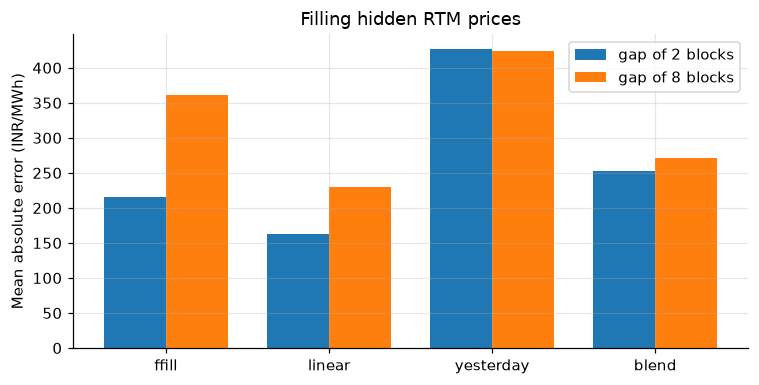

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.6))
width = 0.38
names = list(tables[2].index)
x = np.arange(len(names))
ax.bar(x - width / 2, tables[2]["MAE"], width, label="gap of 2 blocks")
ax.bar(x + width / 2, tables[8]["MAE"], width, label="gap of 8 blocks")
ax.set_xticks(x, names)
ax.set_ylabel("Mean absolute error (INR/MWh)")
ax.set_title("Filling hidden RTM prices")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "04_imputation.png")

In [4]:
# Prices before and after the transform. Candidate scales are compared on the first 90 days only.
prices = clean["rtm_price"].dropna().to_numpy()
train = prices[7 * 96 : (7 + params.asinh_train_days) * 96]
rows = []
for scale in params.asinh_scales:
    rows.append(
        {
            "scale": scale,
            "skew on first 90 days": pd.Series(np.arcsinh(train / scale)).skew(),
            "skew on all days": pd.Series(np.arcsinh(prices / scale)).skew(),
        }
    )
skew_table = pd.DataFrame(rows).set_index("scale")
skew_table.loc["log", :] = [pd.Series(np.log(train)).skew(), pd.Series(np.log(prices)).skew()]
print(
    "raw skew: first 90 days",
    round(pd.Series(train).skew(), 3),
    "| all days",
    round(pd.Series(prices).skew(), 3),
)
print(skew_table.round(3).to_string())
chosen = choose_scale(train, params.asinh_scales)
print("scale chosen on the first 90 days:", chosen)

raw skew: first 90 days 1.532 | all days 1.621
        skew on first 90 days  skew on all days
scale                                          
50.0                   -0.383            -0.214
100.0                  -0.376            -0.207
250.0                  -0.331            -0.167
500.0                  -0.214            -0.060
1000.0                  0.041             0.176
2000.0                  0.449             0.564
log                    -0.386            -0.216
scale chosen on the first 90 days: 1000.0


The prices have a long right tail (skew 1.621 over all days). The arcsinh transform is close to a logarithm for these prices (all prices are above 399). I compare candidate scales on the first 90 days only, so the choice does not look at later days.
The scale with the most symmetric result is 1000, which brings the skew on those days from 1.532 to 0.041. The plain logarithm gives -0.386. All the candidates up to 1000 remove most of the skew, so the exact scale matters little. I keep arcsinh because it also works for zero and negative prices, which the log does not.

round trip error: 1.8189894035458565e-12


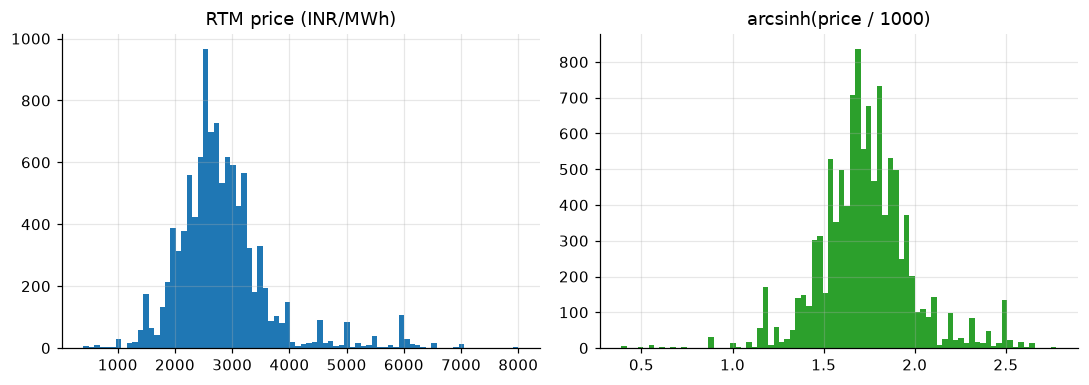

In [5]:
transform = AsinhTransform(chosen)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(prices, bins=80)
axes[0].set_title("RTM price (INR/MWh)")
axes[1].hist(transform.forward(prices), bins=80, color="tab:green")
axes[1].set_title(f"arcsinh(price / {chosen:.0f})")
fig.tight_layout()
fig.savefig(FIG / "04_transform.png")
print(
    "round trip error:", float(np.abs(transform.inverse(transform.forward(prices)) - prices).max())
)

After the transform the distribution is much closer to symmetric. The transform can be undone exactly (largest round-trip error 1.8e-12). Whether it helps a model is a question for step 2.5, where it is one of the settings I compare.

In [6]:
# Holidays: the list used in 2021 against the official list
old = {"2020-10-02", "2020-10-25", "2020-10-30", "2020-11-14", "2020-12-25", "2020-12-31"}
official = {d.isoformat() for d in holidays if "2020-10-01" <= d.isoformat() <= "2021-01-19"}
print("official, in the data window:", sorted(official))
print("used in 2021 but not on the official list:", sorted(old - official))
print("on the official list but not used in 2021:", sorted(official - old))

official, in the data window: ['2020-10-02', '2020-10-25', '2020-10-30', '2020-11-14', '2020-11-30', '2020-12-25']
used in 2021 but not on the official list: ['2020-12-31']
on the official list but not used in 2021: ['2020-11-30']


The holiday list in my first notebook had two problems. It left out 30 November (Guru Nanak's Birthday) and it included 31 December, which is not on the official central government list. It also labelled 30 October "Good Friday". That day is Milad-un-Nabi, and Good Friday was on 10 April.
The list in `config/holidays.yaml` comes from the 2020 list of the Department of Personnel and Training. It covers central government holidays only, not state or restricted holidays.

In [7]:
# Demand rows that should not be trusted, by reason
early = clean["date"].dt.date < params.demand_reliable_from
stale = stale_mask(clean["demand"], params.stale_min_blocks)
copied = np.zeros(len(clean), dtype=bool)
for _, later in identical_days(clean, "demand"):
    copied |= (clean["date"].dt.strftime("%Y-%m-%d") == later).to_numpy()
suspect = demand_suspect(clean, params)
print(
    "before",
    params.demand_reliable_from,
    ":",
    int(early.sum()),
    "| runs of 4+ identical values:",
    int(stale.sum()),
    "| copied days:",
    int(copied.sum()),
)
print("rows flagged in total:", int(suspect.sum()), "of", len(clean))

before 2020-10-16 : 1440 | runs of 4+ identical values: 359 | copied days: 288
rows flagged in total: 2087 of 10656


Demand has 2087 rows that I do not trust: the first 15 days (1440 rows), runs of four or more identical values (359 rows) and the second day of each pair of identical days (288 rows). They do not overlap. By default the feature builder sets demand to missing on those rows, so a model never sees them. Setting `demand_policy` to `keep` uses the demand as published.

In [8]:
features = build_features(clean, params, holidays)
groups = feature_groups(params)
print(
    "feature table:",
    features.shape,
    "| days",
    features["date"].min().date(),
    "to",
    features["date"].max().date(),
)
print("rows without a published target:", int((~features["target_observed"]).sum()))
print({k: len(v) for k, v in groups.items()})
missing = features.isna().sum()
print("inputs with missing values:", missing[missing > 0].to_dict())
features[
    [
        "date",
        "block",
        "rtm_price",
        "dam_price",
        "rtm_price_lag1d",
        "rtm_price_lag7d",
        "rtm_dam_spread_lag1d",
        "is_holiday",
    ]
].head(4)

feature table: (9984, 24) | days 2020-10-08 to 2021-01-19
rows without a published target: 8
{'calendar': 3, 'dam_today': 5, 'dam_change': 1, 'rtm_lags': 8, 'spread_lag': 1, 'demand_lags': 2}
inputs with missing values: {'rtm_price': 8, 'demand_lag1d': 1500, 'demand_lag7d': 2067}


,date,block,rtm_price,dam_price,rtm_price_lag1d,rtm_price_lag7d,rtm_dam_spread_lag1d,is_holiday
0,2020-10-08,1,3921.56,2849.39,3673.80,2089.45,1173.50,0
1,2020-10-08,2,3921.12,2804.69,3673.08,2245.41,1172.76,0
2,2020-10-08,3,3214.28,2802.65,3199.19,2245.89,662.78,0
3,2020-10-08,4,3199.59,2749.39,3199.29,2245.91,749.07,0


The feature table has one row per day and block, from 8 October 2020 to 19 January 2021 (9984 rows). The first seven days are used only to build lags. The inputs are the DAM price and volumes of the forecast day, simple summaries of that day's DAM prices, the RTM price and bids of the previous day and of the same day a week earlier, the previous day's mean and spread of RTM prices, yesterday's RTM minus DAM price, demand a day and a week earlier, and the block, day of week and a holiday flag.
Eight rows have no published target, and they are kept with `target_observed` set to False. Models will not train on them. The gaps are filled only inside the lagged inputs. The only inputs with missing values are the two demand lags, where the demand was masked.

dam_price                 0.772
rtm_price_lag1d           0.764
demand_lag1d              0.730
dam_purchase_bid          0.726
demand_lag7d              0.658
rtm_price_lag7d           0.534
rtm_purchase_bid_lag1d    0.501
block                     0.330
dtype: float64

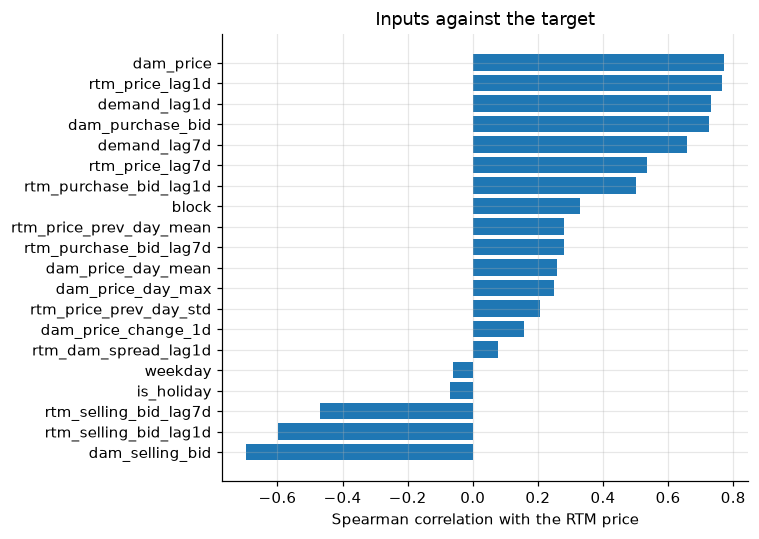

In [9]:
# Rank correlation of each input with the price (a first look, not a model)
usable = features[features["target_observed"]]
names = [n for group in groups.values() for n in group]
corr = usable[names].corrwith(usable["rtm_price"], method="spearman").sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(corr.index, corr.values)
ax.set_xlabel("Spearman correlation with the RTM price")
ax.set_title("Inputs against the target")
fig.tight_layout()
fig.savefig(FIG / "04_input_correlation.png")
corr.sort_values(ascending=False).round(3).head(8)

A first look at how the inputs relate to the price, using rank correlation. This is not a model. The DAM price of the same block (0.772) and yesterday's RTM price (0.764) are the strongest. Demand a day earlier follows (0.730), and the DAM purchase volume (0.726).
The DAM selling volume is the strongest negative one (about -0.7 in the figure): more supply offered in the day-ahead market goes with lower prices. That fits my reading of the bid columns as volumes.

In [10]:
# No input may use information from the forecast day or later (the full tests are in tests/test_features.py).
cut = pd.Timestamp("2020-12-10")
changed = clean.copy()
unknown = changed["date"] >= cut
for column in ("rtm_price", "rtm_purchase_bid", "rtm_selling_bid", "demand"):
    changed.loc[unknown, column] = changed.loc[unknown, column] * 1.7 + 123
later = changed["date"] > cut
for column in ("dam_price", "dam_purchase_bid", "dam_selling_bid"):
    changed.loc[later, column] = changed.loc[later, column] * 1.7 + 123
altered = build_features(changed, params, holidays)
day = features["date"] == cut
inputs = [c for c in features.columns if c not in ("rtm_price", "target_observed")]
same = (
    altered.loc[day, inputs]
    .reset_index(drop=True)
    .equals(features.loc[day, inputs].reset_index(drop=True))
)
print("inputs for", cut.date(), "unchanged after scrambling everything not yet known:", same)

inputs for 2020-12-10 unchanged after scrambling everything not yet known: True


**What I understand.** Every input is known at the time of the forecast. I check that by scrambling everything a forecaster could not yet know (RTM and demand from the forecast day on, DAM after it) and confirming the inputs of the forecast day do not change.
The tests in `tests/test_features.py` do this for three days, and also confirm that a fill never looks into the next day. I also confirmed that these tests fail when the fill does look ahead. Straight-line fill beats forward fill, so the first notebook's way of handling the gaps was not the best one. Demand needs care, and I will compare models with and without it in step 2.5.